# NUDGE quickstart

NUDGE finds single-time interventions: it identifies controllers that set the states of a few nodes for one timestep, then lets the network's natural dynamics drive it to a desired phenotype. NUDGE also ranks these controllers by robustness and explains their mechanism.

This tutorial reproduces the toy example of the NUDGE paper (PNAS 2026, [doi:10.1073/pnas.2604777123](https://doi.org/10.1073/pnas.2604777123), SI Appendix section S2 and Fig. S1). It follows the four NUDGE steps:
1. Define the objective node.
2. Find the minimal controllers.
3. Rank them by robustness.
4. Explain the mechanism.

In [1]:
# NUDGE relies on a parameter file, which is loaded here. Parameters can also be manually changed.

import os, logging
logging.getLogger('colomoto_jupyter').setLevel(logging.ERROR)  # hide the optional ipylab notice
import nudge
from nudge import plot
from colomoto import minibn
from nudge import util

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')  # run from the repository root so the input paths resolve
params = util.load_yaml('input/params.yaml')
params.update({
    'network_file': 'input/networks/toy.bnet',
    'target': 'Y',               # desired phenotype: Y = 1
    'seed': 0,                  
    'measure_robustness': True,  # robustness and mechanism may take extra runtime on larger networks
    'find_mechanism': True,
    'plot_mechanism': False,     # the mechanism graph is drawn below instead
    'verbose_nudge': False,
})

## Step I: Network and objective
NUDGE also requires a network file, which is read as a CoLoMoTo `minibn.BooleanNetwork` and is assumed to update synchronously. The toy network has 4 nodes plus an objective node. `A` is an input with a self-loop. `C` and `D` are the phenotype markers. The desired phenotype is `C = D = 1`, so the objective node is `Y = C & D`, and the goal is to drive the network to attractors where `Y = 1`. Note that the objective node is specified in `params['target']` and must exist in the network file.

In [2]:
bn = minibn.BooleanNetwork.load(params['network_file'])

In [3]:
bn

A <- A
B <- A|B
C <- (A&D)|(B&C)|(B&D)
D <- (A&C)|(B&C)|(A&!D)|(B&!D)
Y <- C&D

## Step II: Find controllers
`nudge.control` applies the recursive self-composite (RSC) method to `Y`. RSC repeatedly substitutes each node's update rule into `Y`'s function and simplifies the result, until the function stops changing. That final form is the terminal logic, which maps any initial state to the value `Y` takes in the attractor that state reaches. Its clauses are exactly the valid single-time interventions (SI Theorem 1, Corollary 1). For this network the terminal logic is `A | B`, so setting either `A = 1` or `B = 1` for a single timestep is enough. If the parameter file requires robustness and mechanism, they are computed in the same call (see below).

`nudge.control` returns two things:
- `strategies`: the best controllers as CoLoMoTo `algorecell_types` reprogramming strategies, using the original node names. The best controllers are those with the fewest nodes and, among those, the highest robustness bound.
- `details`: a dictionary with every controller found, the robustness bounds, and the mechanism data used below.

In [4]:
strategies, details = nudge.control(params)
strategies.as_table()

,A
0,1


To list every controller rather than only the best ones, convert `details['all controllers']`:

In [5]:
nudge.to_strategies(details['all controllers'], params['original_names']).as_table()

,A,B
0,,1
1,1,


## Step III: Robustness
Both `A = 1` and `B = 1` are minimal controllers of size 1, so NUDGE breaks the tie by robustness (SI section S4).

**Self-reinforced motifs.** After a single-time intervention, the phenotype can only last if the network's own dynamics keep it in place. A **self-reinforced motif** is a logical expression that, once satisfied, guarantees convergence to an attractor where it stays satisfied (SI Definition 1). A motif can be a disjunction of clauses: `A | B` can stay true even if `A` and `B` individually oscillate. Any controllable objective needs at least one such motif (SI Lemma 2).

**Robustness.** The relative distance `r` of an attractor is the fewest node flips that move it out of the basin of the `Y = 1` attractors. A controller's robustness `R` is the smallest `r` among the attractors the controller can reach (SI Definitions 2 and 3).

**What NUDGE computes.** Computing `R` directly requires simulation. NUDGE instead computes a lower bound on `R` from the terminal logic (SI Theorem 2):
1. **Candidate motifs** are the clauses of `Y`'s terminal logic and their disjunctions, up to `analysis_order` clauses (SI Lemma 1). Here they are `A`, `B` and `A | B`.
2. RSC is run on each candidate `M` to get its own terminal logic `G_M`. `M` is self-reinforced if `M` implies `G_M`. A controller **drives** `M` if the controller implies `G_M`.
3. To leave the phenotype, a perturbation must flip at least one node of every motif the controller drives. The bound is therefore the size of the smallest set of nodes that hits every driven motif (a minimum hitting set).

NUDGE reports this bound as each controller's relative distance. It is stored in `details['relative distances']`, in the same order as `details['min controllers']`:

In [6]:
for cnt, distance in zip(details['min controllers'], details['relative distances']):
    print(' & '.join(cnt), '= 1   relative distance:', distance)

A = 1   relative distance: 2
B = 1   relative distance: 1


`A` drives `A`, `B` and `A | B`, so the smallest hitting set is `{A, B}` and the bound is 2. `B` drives only `B` and `A | B`, so the smallest hitting set is `{B}` and the bound is 1. The bound is not always tight: flipping a node in a motif is necessary to break the motif, but not always sufficient. Here, controlling A is more robust, and NUDGE returns it as the best controller.

## Step IV: Mechanism
The mechanism explains how a single-time intervention leads to a lasting phenotype (SI section S5). It consists of three types of **multipaths**, each showing how a sender clause eventually drives a receiver clause:
- **controller -> self-reinforced**: how the controller drives self-reinforced motifs.
- **self-reinforced -> self-reinforced**: how brief activation of each motif leads to its permanent activation.
- **self-reinforced -> target**: how each motif guarantees `Y = 1`.

Each multipath is built by tracing the RSC sequence of the receiver backwards, which corresponds to moving forwards in time, and keeping only the clauses that the sender drives. Each entry in `details['mechanism data'][controller]` is a `(motif, order)` pair. The **order** is the largest disjunction size needed along that multipath (see the blue arrows below). Order 0 means no path was found within `analysis_order`. Higher orders become rapidly computationally intractable so an exact mechanism may not always be feasible.

Here we look at the mechanism of the best controller, `A`:

A drives motif           A      order 1
A drives motif           B      order 1
motif reinforces itself  A      order 1
motif reinforces itself  B      order 1
motif drives Y           A      order 2
motif drives Y           B      order 2


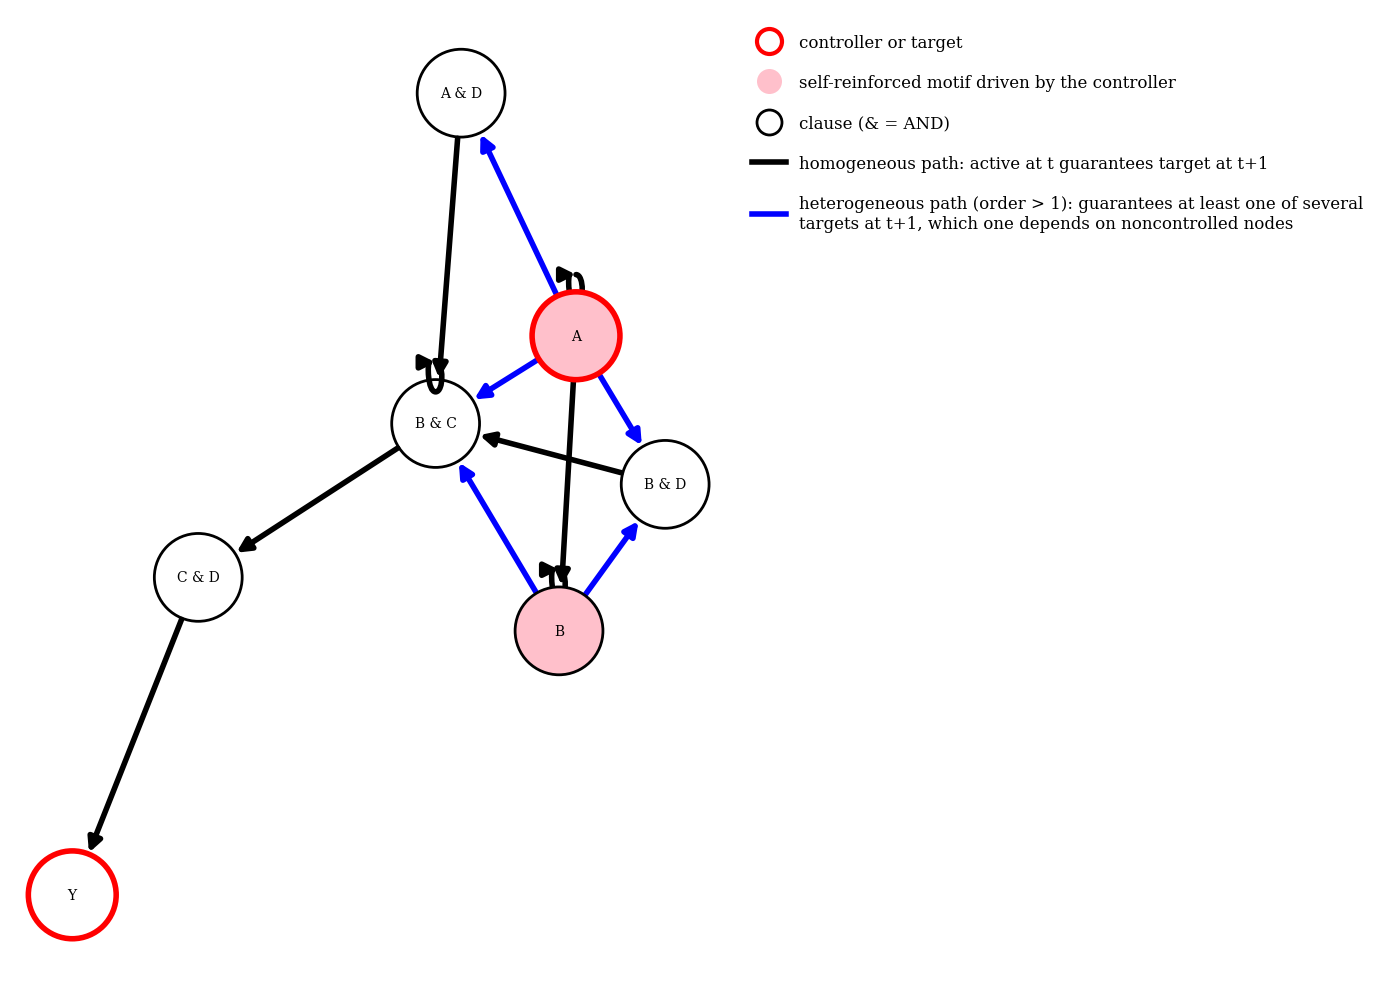

In [8]:
mech = details['mechanism data']['A']
labels = {'controller -> self-reinforced': 'A drives motif',
          'self-reinforced -> self-reinforced': 'motif reinforces itself',
          'self-reinforced -> target': 'motif drives Y'}
for key, text in labels.items():
    for motif, order in mech[key]:
        print(f'{text:24s} {motif:6s} order {order}')
plot.mechanism_graph(params, mech['graph'])

**Reading the graph.** Each vertex is a clause, which is a conjunction of node states, so `B&C` means `B = 1` and `C = 1`. An arrow `u -> v` means that if `u` is active at time `t`, `v` is active at `t + 1`.
- **Red outline**: the controller (`A`) and the target (`Y`).
- **Pink fill**: the self-reinforced motifs activated by the controller, taken from the candidate motifs in step III (`A` and `B`).
- **Black arrow** (order 1, homogeneous path): the source alone guarantees the next clause.
- **Blue arrow** (order > 1, heterogeneous path): the source guarantees that at least one of a group of clauses becomes active, but not all of them. Which one becomes active depends on noncontrolled nodes, so a population of cells can respond heterogeneously to the same intervention (SI section S5.2).

**The heterogeneous path in this example.** Starting from `A = 1`, the route to `B&C` depends on the state of `D`. In both cases `B = 1` at the next step, because `B = A | B`:
- If `D = 1`, then `C = 1` at the next step (`C = A & D`), so `B&C` is activated directly.
- If `D = 0`, then `D = 1` at the next step (`D = A & !D`), which activates `A&D` and `B&D`. Both of these then activate `B&C`.

`B&C` then activates `C&D`, which activates `Y`. `B&C` also keeps itself on (its self-loop), because `B = A | B` and `C`'s rule contains the clause `B & C`. It is not shaded because it is not a candidate motif: candidates are built from the clauses of `Y`'s terminal logic (`A | B`). Any state with `B&C` already satisfies the motif `B`.

**Why `A` is more robust than `B`.** The graph shows that `A` drives two self-reinforced motifs: `A` itself through `A = A`, and `B`, which `A` turns on through `B = A | B` and which then holds itself on. Either one alone is enough to sustain `Y`, so a perturbation must break both. That requires flipping `A` and `B`, which gives the bound of 2. Controlling `B` drives only the motif `B`. `B` can never turn `A` on, because `A` depends only on itself, so flipping `B` alone is enough to lose `Y`.